<a href="https://colab.research.google.com/github/KP-365/hybrid-ope-lending/blob/main/hybrid_dr_generator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Import and download files and data

In [13]:
!pip install sdv xgboost -q
!pip install ctgan -q

In [8]:
import os
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss
import time
from sdv.metadata import Metadata
from sdv.single_table import TVAESynthesizer
import sdv; print(sdv.__version__)


SAMPLE = 1.0                      # 0.05 for a smoke run
CUTOFFS = [700, 680, 660, 650, 640, 630, 620]
CAPS = [None, 100, 50, 20, 10]    # None = no cap
P_FLOOR = 1e-6                    # stops a propensity of exactly 0 giving an infinite weight
X_features = ['amount', 'purpose', 'risk_score', 'dti', 'zip3', 'state']
cat_cols = ['purpose', 'zip3', 'state']

2.2.0


In [9]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/hybrid-ope-lending'
except ImportError:
    DATA_DIR = os.environ.get('LOCAL_DATA_DIR', '.')

combined = pd.read_parquet(f'{DATA_DIR}/lending_club_combined.parquet')
outcome_df = pd.read_parquet(f'{DATA_DIR}/lending_club_outcome.parquet')

# Model 1 (propensity). enable_categorical must be True or XGBoost refuses category columns.
m1 = xgb.XGBClassifier(tree_method='hist', enable_categorical=True)
m1.load_model(f'{DATA_DIR}/propensity_model.json')
m1_feat = m1.get_booster().feature_names
print('Model 1 expects, in this order:', m1_feat)
print('missing from combined:', [c for c in m1_feat if c not in combined.columns])
print('missing from outcome :', [c for c in m1_feat if c not in outcome_df.columns])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model 1 expects, in this order: ['amount', 'purpose', 'risk_score', 'dti', 'zip3', 'state', 'year', 'month']
missing from combined: []
missing from outcome : []


In [10]:

out = outcome_df[outcome_df['risk_score'].notna()].copy()
out['risk_score'] = out['risk_score'] // 5 * 5
out = out[out['year'] <= 2014]


if SAMPLE < 1.0:                         # same fraction in both so the weights stay consistent
    out = out.sample(frac=SAMPLE, random_state=0)

N = len(out)                            # scored applicants in the OPE period
print('applicants N:', N, ' accepted loans with outcomes:', len(out))
print('default rate in out:', out['default'].mean().round(4))

applicants N: 358894  accepted loans with outcomes: 358894
default rate in out: 0.1387


## 2. Define the methods

In [11]:
def true_value(df, cutoff):
    return ((df['risk_score'] >= cutoff) & (df['default'] == 0)).mean()

def thin(df, seed, q_low=0.02):
    rng = np.random.default_rng(seed)
    probability = np.select([df['risk_score'] >= 700, df['risk_score'] >= 680, df['risk_score'] >= 660],
                            [1.0, 0.5, q_low], default=0.0)
    kept = rng.random(len(df)) < probability
    return kept, probability

def fit_outcome(df, kept, features):
    train = df[kept]
    model = xgb.XGBClassifier(tree_method='hist', enable_categorical=True,
                              max_depth=3, learning_rate=0.05, min_child_weight=50)
    model.fit(train[features], train['default'])
    return 1 - model.predict_proba(df[features])[:, 1]

def dm(df, m, cutoff):
    approved = (df['risk_score'] >= cutoff).to_numpy()
    return np.sum(m[approved]) / len(df)

def dr(df, kept, probability, m, cutoff):
    approved = df['risk_score'].to_numpy() >= cutoff
    use = kept & approved
    reward = 1 - df['default'].to_numpy()
    weight = 1 / probability[use]
    return dm(df, m, cutoff) + np.sum(weight * (reward[use] - m[use])) / len(df)

def dr_contributions(df, kept, probability, m, cutoff):
    approved = df['risk_score'].to_numpy() >= cutoff
    use = kept & approved
    reward = 1 - df['default'].to_numpy()
    phi = np.zeros(len(df))
    phi[approved] = m[approved]
    phi[use] += (1 / probability[use]) * (reward[use] - m[use])
    return phi

def bayes_boot(phi, n_draws=200, seed=0):
    rng = np.random.default_rng(seed)
    estimates = np.array([np.sum(rng.dirichlet(np.ones(len(phi))) * phi) for _ in range(n_draws)])
    return np.percentile(estimates, [2.5, 97.5])

truths = {c: true_value(out, c) for c in [700, 680, 660]}
print(truths)

{700: np.float64(0.36051870468717784), 680: np.float64(0.5946741934944579), 660: np.float64(0.8603877467998908)}


In [17]:
gen_cols = ['amount', 'purpose', 'risk_score', 'dti']
features = ['amount', 'purpose', 'risk_score', 'dti', 'zip3', 'state']

# 3. Train and test the generator

In [14]:
from ctgan import TVAE


kept, probability = thin(out, 0, 0.002)
near = kept & (out['risk_score'] >= 660).to_numpy() & (out['risk_score'] < 720).to_numpy()
train_gen = out.loc[near, gen_cols].sample(min(20000, near.sum()), random_state=0).reset_index(drop=True)
train_gen['purpose'] = train_gen['purpose'].astype(str)
train_gen = train_gen.dropna()

t = time.time()
synth = TVAE(epochs=50)
synth.fit(train_gen, discrete_columns=['purpose'])
syn = synth.sample(20000)
print(round(time.time() - t), 'seconds')
print(syn.describe().round(2))
print(train_gen.describe().round(2))

41 seconds
         amount  risk_score       dti
count  20000.00    20000.00  20000.00
mean    9516.60      700.15     13.05
std     4597.80        4.54      3.66
min       72.69      679.67     -1.32
25%     6054.24      699.97     10.87
50%     9230.74      700.00     13.46
75%    13462.00      700.03     15.52
max    26123.85      710.19     27.42
         amount  risk_score       dti
count  20000.00    20000.00  20000.00
mean   13202.65      698.16     17.24
std     7840.53       11.31      7.65
min      500.00      660.00      0.00
25%     7200.00      690.00     11.52
50%    11500.00      700.00     16.91
75%    18000.00      705.00     22.57
max    35000.00      715.00     39.92


In [15]:
rng = np.random.default_rng(0)
idx = np.where(near)[0]
w = 1 / probability[idx]
pick = rng.choice(idx, size=20000, replace=True, p=w / w.sum())
train_gen = out.iloc[pick][gen_cols].reset_index(drop=True)
train_gen['purpose'] = train_gen['purpose'].astype(str)
train_gen['risk_score'] = train_gen['risk_score'].astype(int).astype(str)
train_gen = train_gen.dropna()

t = time.time()
synth = TVAE(epochs=150)
synth.fit(train_gen, discrete_columns=['purpose', 'risk_score'])
syn = synth.sample(20000)
syn['risk_score'] = syn['risk_score'].astype(int)
print(round(time.time() - t), 'seconds')
print('share of synthetic in 660-679:', ((syn['risk_score'] >= 660) & (syn['risk_score'] < 680)).mean().round(3))
print('share of real (population) in 660-679:',
      ((out['risk_score'] >= 660) & (out['risk_score'] < 680))[(out['risk_score'] >= 660) & (out['risk_score'] < 720)].mean().round(3))
print(syn.describe().round(2))

78 seconds
share of synthetic in 660-679: 0.593
share of real (population) in 660-679: 0.413
         amount  risk_score       dti
count  20000.00    20000.00  20000.00
mean   12579.94      674.63     16.55
std     7541.31       10.26      7.21
min        0.18      660.00     -0.19
25%     7426.04      665.00     10.80
50%    10097.67      675.00     16.43
75%    15435.01      685.00     21.85
max    35948.22      715.00     39.39


In [16]:
from sklearn.neighbors import NearestNeighbors

def fit_outcome_model(df, kept, features):
    model = xgb.XGBClassifier(tree_method='hist', enable_categorical=True,
                              max_depth=3, learning_rate=0.05, min_child_weight=50)
    model.fit(df[kept][features], df[kept]['default'])
    return model

def train_generator(df, kept, probability, seed, epochs=150):
    rng = np.random.default_rng(seed)
    near = kept & (df['risk_score'] >= 660).to_numpy() & (df['risk_score'] < 720).to_numpy()
    idx = np.where(near)[0]
    w = 1 / probability[idx]
    pick = rng.choice(idx, size=20000, replace=True, p=w / w.sum())
    tg = df.iloc[pick][gen_cols].reset_index(drop=True).dropna()
    tg['purpose'] = tg['purpose'].astype(str)
    tg['risk_score'] = tg['risk_score'].astype(int).astype(str)
    g = TVAE(epochs=epochs)
    g.fit(tg, discrete_columns=['purpose', 'risk_score'])
    syn = g.sample(20000)
    syn['risk_score'] = syn['risk_score'].astype(int)
    syn['amount'] = syn['amount'].clip(lower=500)
    syn['dti'] = syn['dti'].clip(lower=0)
    return syn

def make_partners(df, kept, probability, q_low, syn):
    band_idx = np.where(kept & (probability == q_low))[0]
    real = df.iloc[band_idx]
    pool = syn[(syn['risk_score'] >= 660) & (syn['risk_score'] < 680)].reset_index(drop=True)
    num = ['amount', 'risk_score', 'dti']
    mu, sd = real[num].mean(), real[num].std()
    nn = NearestNeighbors(n_neighbors=1).fit(((pool[num] - mu) / sd).to_numpy())
    dist, j = nn.kneighbors(((real[num] - mu) / sd).to_numpy())
    partners = pool.iloc[j[:, 0]].reset_index(drop=True)
    partners['zip3'] = real['zip3'].to_numpy()
    partners['state'] = real['state'].to_numpy()
    partners = partners[features].astype(df[features].dtypes.to_dict())
    return band_idx, partners, dist[:, 0]

def hybrid_contributions(df, kept, probability, m, m_syn, band_idx, cutoff, q_low):
    phi = dr_contributions(df, kept, probability, m, cutoff)
    r = 1 - df['default'].to_numpy()[band_idx]
    mb = m[band_idx]
    phi[band_idx] += (1 / q_low) * (-0.5 * (r - mb) + 0.5 * (m_syn - mb))
    return phi

In [18]:
rows = []
for q_low in [0.005, 0.002]:
    for seed in range(10):
        kept, probability = thin(out, seed, q_low)
        model = fit_outcome_model(out, kept, features)
        m = 1 - model.predict_proba(out[features])[:, 1]
        syn = train_generator(out, kept, probability, seed)
        band_idx, partners, dist = make_partners(out, kept, probability, q_low, syn)
        m_syn = 1 - model.predict_proba(partners)[:, 1]

        phi_dr = dr_contributions(out, kept, probability, m, 660)
        phi_hy = hybrid_contributions(out, kept, probability, m, m_syn, band_idx, 660, q_low)
        for name, phi in [('DR', phi_dr), ('Hybrid', phi_hy)]:
            low, high = bayes_boot(phi, n_draws=100, seed=seed)
            rows.append({'q_low': q_low, 'seed': seed, 'estimator': name,
                         'error': phi.mean() - truths[660],
                         'covered': low <= truths[660] <= high, 'width': high - low,
                         'median_dist': np.median(dist)})
        print(q_low, seed, 'done')

res = pd.DataFrame(rows)
res.groupby(['q_low', 'estimator']).agg(
    bias=('error', 'mean'),
    rmse=('error', lambda x: (x**2).mean()**0.5),
    coverage=('covered', 'mean'),
    width=('width', 'mean'),
    median_dist=('median_dist', 'mean')).round(4)

0.005 0 done
0.005 1 done
0.005 2 done
0.005 3 done
0.005 4 done
0.005 5 done
0.005 6 done
0.005 7 done
0.005 8 done
0.005 9 done
0.002 0 done
0.002 1 done
0.002 2 done
0.002 3 done
0.002 4 done
0.002 5 done
0.002 6 done
0.002 7 done
0.002 8 done
0.002 9 done


bias    rmse  coverage   width  median_dist
q_low estimator                                               
0.002 DR         0.0014  0.0081       0.9  0.0306       0.0269
      Hybrid     0.0059  0.0071       0.8  0.0154       0.0269
0.005 DR         0.0003  0.0046       1.0  0.0193       0.0373
      Hybrid     0.0054  0.0059       0.5  0.0099       0.0373

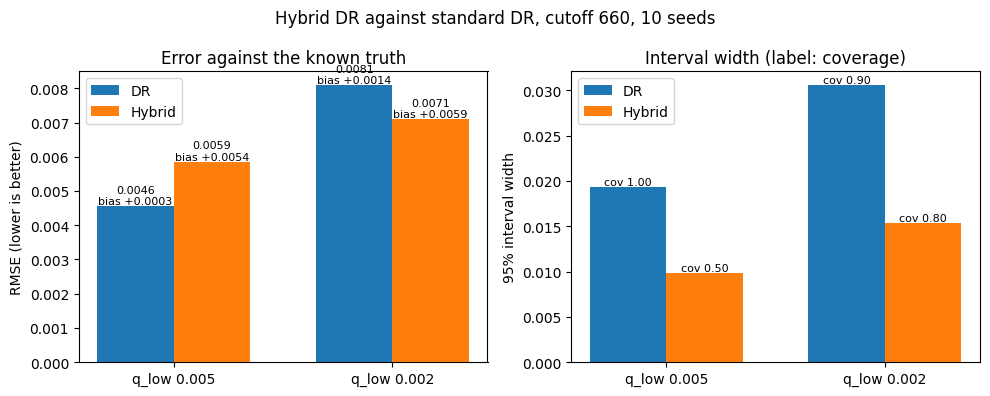

In [24]:
import matplotlib.pyplot as plt

s = res.groupby(['q_low', 'estimator']).agg(
    bias=('error', 'mean'),
    rmse=('error', lambda x: (x**2).mean()**0.5),
    coverage=('covered', 'mean'),
    width=('width', 'mean')).reset_index()
s['q_low'] = s['q_low'].round(3)

qs = [0.005, 0.002]
x = np.arange(len(qs))
bw = 0.35
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for i, est in enumerate(['DR', 'Hybrid']):
    d = s[s['estimator'] == est].set_index('q_low').reindex(qs)
    pos = x + (i - 0.5) * bw
    axes[0].bar(pos, d['rmse'], bw, label=est)
    axes[1].bar(pos, d['width'], bw, label=est)
    for p, r, b, w, c in zip(pos, d['rmse'], d['bias'], d['width'], d['coverage']):
        axes[0].text(p, r, f'{r:.4f}\nbias {b:+.4f}', ha='center', va='bottom', fontsize=8)
        axes[1].text(p, w, f'cov {c:.2f}', ha='center', va='bottom', fontsize=8)

for ax, ylab, title in [(axes[0], 'RMSE (lower is better)', 'Error against the known truth'),
                        (axes[1], '95% interval width', 'Interval width (label: coverage)')]:
    ax.set_xticks(x)
    ax.set_xticklabels([f'q_low {q}' for q in qs])
    ax.set_ylabel(ylab)
    ax.set_title(title)
    ax.legend()

fig.suptitle('Hybrid DR against standard DR, cutoff 660, 10 seeds')
plt.tight_layout()
plt.savefig('hybrid_vs_dr.png', dpi=200)
plt.show()